# Week 12 — Data Visualization with Matplotlib
**Learning outcomes**
CPMK 3. Able to process and analyze data using existing software packages.

**Instructions:** Run the code cells in order. Read the explanations and complete the independent exercises before reading the answer key.

`matplotlib.pyplot` `plt.subplots()` `Figure` `Axes` `ax.plot()` `marker` `linestyle` `legend()` `pandas` `DatetimeIndex` `mdates` `annotate()` `ax.bar()` `ax.hist()` `ax.boxplot()` `ax.scatter()` `ax.errorbar()` `plt.style.context()` `fig.savefig()` `dpi` `bbox_inches`

## Table of Contents

1. Introduction to Matplotlib
2. Plotting Time-Series Data
3. Statistical Visualization
4. Saving Figures
5. Independent Student Exercises
6. Meeting Summary and Self-Assessment
7. Google Colab

In [1]:
# Installation (jalankan sekali jika paket belum tersedia)
%pip install matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib: 3.11.0
NumPy: 2.4.6
Pandas: 3.0.3


---
## 1. Introduction to Matplotlib

### 1.1 Understanding Matplotlib, Figure, and Axes

**Matplotlib** merupakan pustaka Python untuk membuat grafik. `pyplot` biasanya diimpor sebagai `plt`. Dalam contoh berikut, **`Figure`** adalah keseluruhan gambar, sedangkan **`Axes`** adalah area tempat data digambarkan.

`plt.subplots()` membuat keduanya sekaligus. Gunakan metode `ax` untuk mengatur isi grafik.

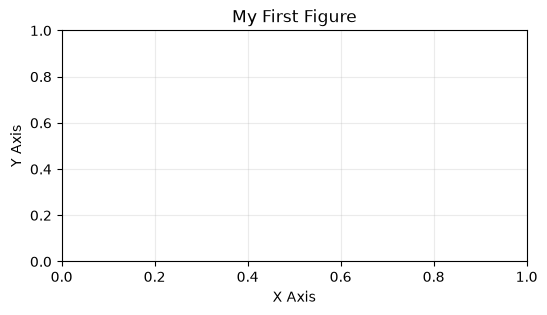

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_title("My First Figure")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.grid(alpha=0.25)
plt.show()

Kode ini menggunakan **Matplotlib** untuk membuat grafik berukuran 6 × 3 inci. `set_title()` mengatur judul, `set_xlabel()` dan `set_ylabel()` memberi nama sumbu, `grid()` menambahkan garis kisi, dan `plt.show()` menampilkan grafik.

### 1.2 Creating a Simple Line Plot

**Line plot** menghubungkan titik-titik data dengan garis. Grafik ini cocok untuk menampilkan urutan pengamatan, seperti perubahan nilai dari minggu ke minggu. Sumbu X menunjukkan minggu, sedangkan sumbu Y menunjukkan nilai.

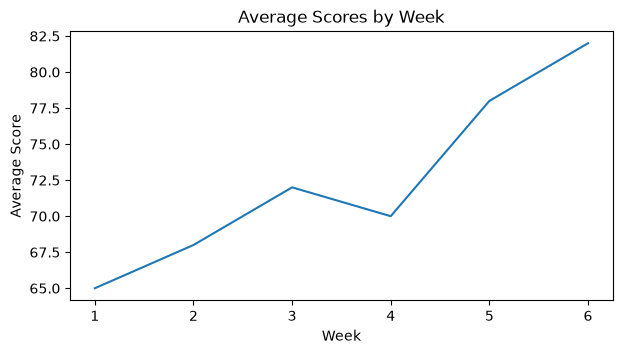

In [10]:
weeks = np.array([1, 2, 3, 4, 5, 6])
average_scores = np.array([65, 68, 72, 70, 78, 82])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()

### 1.3 Customizing Lines, Markers, and Labels

Tampilan grafik bisa diperjelas melalui `color`, `marker`, `linestyle`, dan `label`.

- `marker="o"`: titik pengamatan berbentuk lingkaran.
- `linestyle="--"`: garis putus-putus.
- `ax.legend()`: menampilkan keterangan setiap garis.
- `ax.grid()`: membantu membaca nilai pada sumbu.

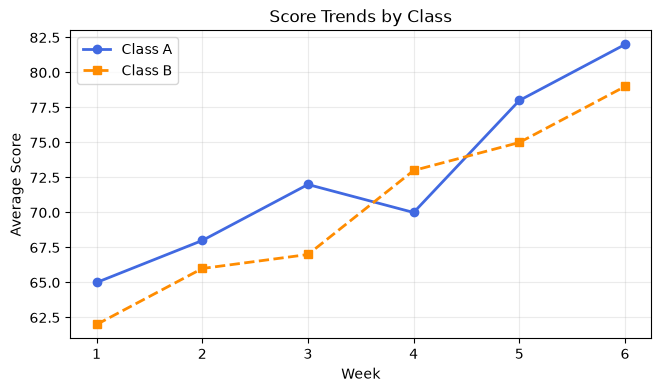

In [11]:
class_a = np.array([65, 68, 72, 70, 78, 82])
class_b = np.array([62, 66, 67, 73, 75, 79])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(weeks, class_a, color="royalblue", marker="o", linewidth=2, label="Class A")
ax.plot(weeks, class_b, color="darkorange", marker="s", linestyle="--", linewidth=2, label="Class B")
#ax set bisa digabung
ax.set(title="Score Trends by Class", xlabel="Week", ylabel="Average Score")
ax.set_xticks(weeks)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### 1.4 Creating Multiple Subplots

Jika ingin membandingkan dua grafik tanpa menumpuk seluruh garis, gunakan `plt.subplots(1, 2)`. Artinya, **satu baris** berisi dua grafik. `axes[0]` mengatur grafik kiri dan `axes[1]` mengatur grafik kanan.

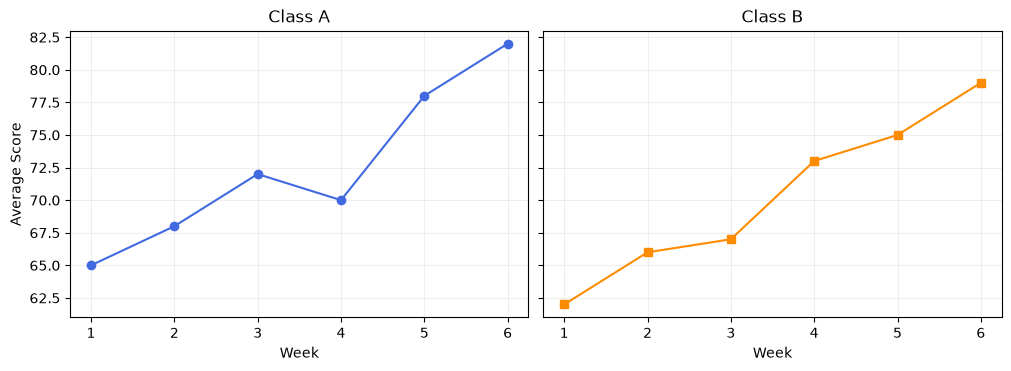

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
axes[0].plot(weeks, class_a, marker="o", color="royalblue")
axes[0].set(title="Class A", xlabel="Week", ylabel="Average Score")

axes[1].plot(weeks, class_b, marker="s", color="darkorange")
axes[1].set(title="Class B", xlabel="Week")
for ax in axes:
    ax.set_xticks(weeks)
    ax.grid(alpha=0.2)
plt.show()

---
## 2. Plotting Time-Series Data

### 2.1 Preparing Dates and Observations

**Time series** adalah data yang dicatat menurut waktu. Tanggal sebaiknya disimpan dalam format yang dapat dikenali Python sebagai tanggal, misalnya memakai `pd.date_range()`.

Contoh berikut menggunakan **curah hujan dan suhu bulanan simulasi** dari dua variabel. Angka-angka ini hanya untuk latihan.

In [28]:
dates = pd.date_range(start="2026-01-01", periods=12, freq="MS")
rainfall = np.array([245, 218, 230, 275, 310, 185, 145, 125, 165, 235, 290, 265])
temperature = np.array([27.5, 27.8, 28.0, 28.2, 28.1, 28.6, 28.8, 29.0, 28.9, 28.4, 28.0, 27.7])
# dates menjadi index
weather = pd.DataFrame({"Rainfall_mm": rainfall, "Temperature_C": temperature}, index=dates)
weather.index.name = "Date"

print("\nIndex type:", type(weather.index).__name__)
print(weather)


Index type: DatetimeIndex
            Rainfall_mm  Temperature_C
Date                                  
2026-01-01          245           27.5
2026-02-01          218           27.8
2026-03-01          230           28.0
2026-04-01          275           28.2
2026-05-01          310           28.1
2026-06-01          185           28.6
2026-07-01          145           28.8
2026-08-01          125           29.0
2026-09-01          165           28.9
2026-10-01          235           28.4
2026-11-01          290           28.0
2026-12-01          265           27.7


### 2.2 Plotting a Time Series

Gunakan tanggal sebagai sumbu X dan nilai pengamatan sebagai sumbu Y. `MonthLocator` dan `DateFormatter` mengatur posisi serta bentuk label tanggal agar lebih mudah dibaca.

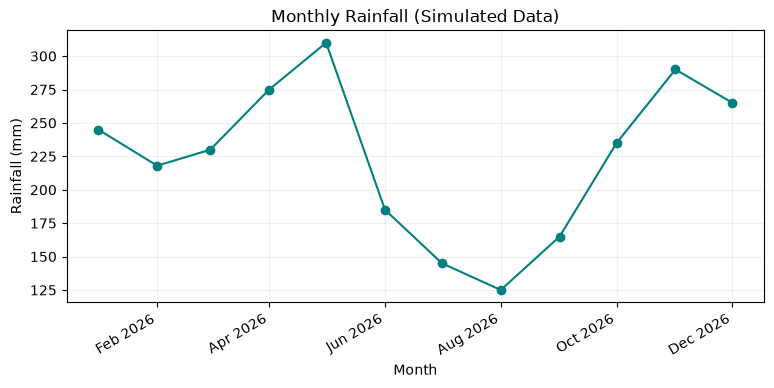

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

Kode ini mengatur tampilan tanggal pada sumbu X. `MonthLocator(interval=2)` menampilkan interval setiap 2 bulan, `DateFormatter("%b %Y")` mengubah format menjadi bulan dan tahun, sedangkan `fig.autofmt_xdate()` merapikan posisi label tanggal agar tidak bertumpuk dalam hal ini miring.

### 2.3 Selecting a Specific Time Period

Kadang kita hanya ingin melihat sebagian periode. Dengan indeks tanggal pada `DataFrame`, `weather.loc["2026-04":"2026-09"]` mengambil data April sampai September 2026.

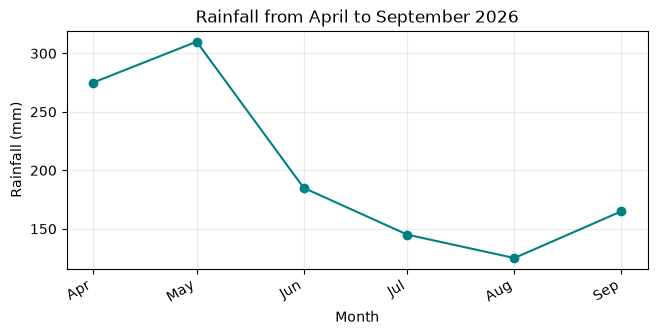

In [9]:
selected_period = weather.loc["2026-04":"2026-09"]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
# disini letak selected period nya
ax.plot(selected_period.index, selected_period["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Rainfall from April to September 2026", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.show()

### 2.4 Comparing Time Series with Different Units

Curah hujan (mm) dan suhu (°C) memiliki **satuan dan skala berbeda**. Dua *subplot* terpisah lebih mudah ditafsirkan dibanding memaksakan kedua variabel pada satu sumbu Y.

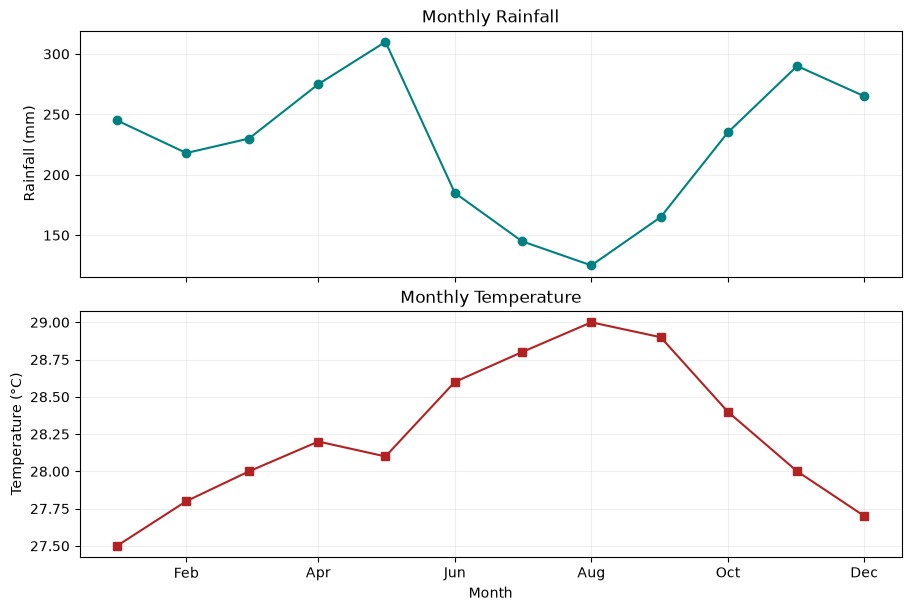

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
axes[0].set(title="Monthly Rainfall", ylabel="Rainfall (mm)")

axes[1].plot(weather.index, weather["Temperature_C"], marker="s", color="firebrick")
axes[1].set(title="Monthly Temperature", xlabel="Month", ylabel="Temperature (°C)")

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

### 2.5 Annotating Important Observations

`ax.annotate()` menambahkan catatan pada titik tertentu. Contoh berikut menandai bulan dengan curah hujan tertinggi

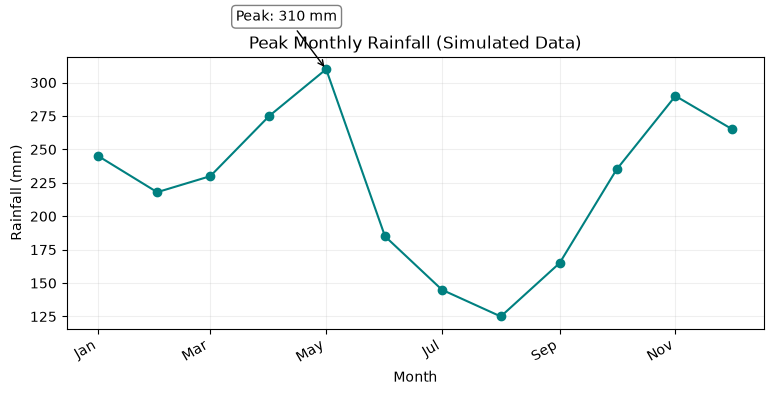

In [11]:
peak_date = weather["Rainfall_mm"].idxmax()
peak_value = weather["Rainfall_mm"].max()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.annotate(f"Peak: {peak_value} mm",
            xy=(peak_date, peak_value), xytext=(-65, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "black"},
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "gray"})
ax.set(title="Peak Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

Kode mencari **curah hujan tertinggi** menggunakan `idxmax()` untuk tanggal dan `max()` untuk nilainya. `ax.annotate()` menambahkan keterangan puncak curah hujan beserta panah dan kotak teks. Kode mengatur anotasi pada grafik. `f"Peak: {peak_value} mm"` menampilkan nilai tertinggi, `xy` menentukan posisi titik, `xytext` mengatur posisi teks, `textcoords` menentukan satuan jarak, `arrowprops` mengatur panah, dan `bbox` memberikan kotak latar pada teks.

### 2.6 Using Twin Axes (Optional)

`ax.twinx()` membuat sumbu Y kedua di sisi kanan. Fitur ini berguna ketika dua variabel memiliki kesamaan waktu tetapi berbeda Y. **Hati-hati:** skala yang berbeda. Untuk perbandingan utama bisa menggunakan dua *subplot* sering.

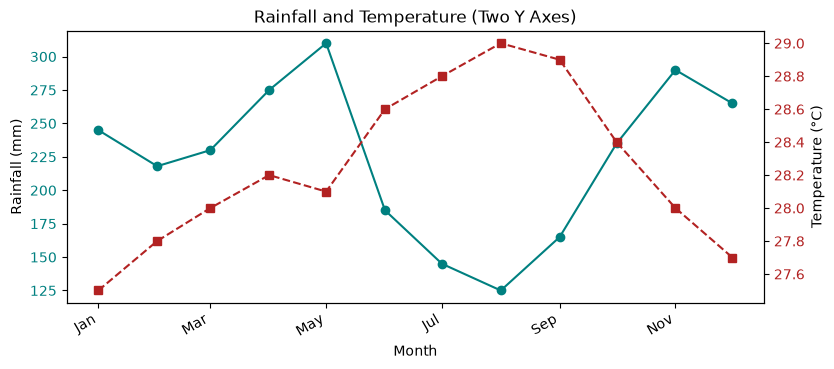

In [12]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()

---
## 3. Statistical Visualization

### 3.1 Preparing Simulated Statistical Data

Visualisasi statistik membantu melihat **perbandingan kelompok, distribusi, sebaran, dan hubungan antarvariabel**. Kita akan menggunakan data nilai dua kelas yang dibuat dengan bilangan acak. `default_rng(12)` membuat angka simulasi  konsisten saat dijalankan ulang.

In [16]:
rng = np.random.default_rng(12)
scores_a = np.clip(rng.normal(loc=78, scale=8, size=40), 0, 100)
scores_b = np.clip(rng.normal(loc=72, scale=10, size=40), 0, 100)
print("Class A: n =", len(scores_a), ", mean =", round(scores_a.mean(), 2))
print("Class B: n =", len(scores_b), ", mean =", round(scores_b.mean(), 2))

Class A: n = 40 , mean = 77.99
Class B: n = 40 , mean = 72.93


`np.clip()` membatasi nilai agar tetap berada pada rentang 0–100.

### 3.2 Creating Bar Charts

**Bar chart** digunakan untuk membandingkan **jumlah atau nilai ringkasan antar kategori**. Pada contoh ini, batang menunjukkan banyaknya mahasiswa simulasi yang memperoleh nilai minimal 75 pada tiap kelas.

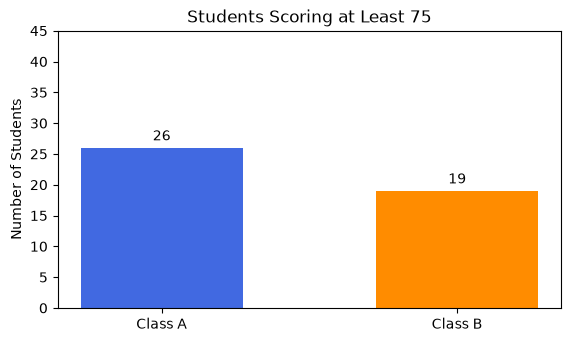

In [17]:
categories = ["Class A", "Class B"]
pass_counts = np.array([(scores_a >= 75).sum(), (scores_b >= 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(categories, pass_counts, color=["royalblue", "darkorange"], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Students Scoring at Least 75", ylabel="Number of Students")
ax.set_ylim(0, len(scores_a) + 5)
plt.show()

In [18]:
pass_counts

array([26, 19])

Kode ax.set_ylim(0, len(scores_a) + 5) mengatur batas sumbu Y mulai dari 0 hingga jumlah data `scores_a` ditambah 5, sehingga rentang sumbu Y menjadi 0–45.

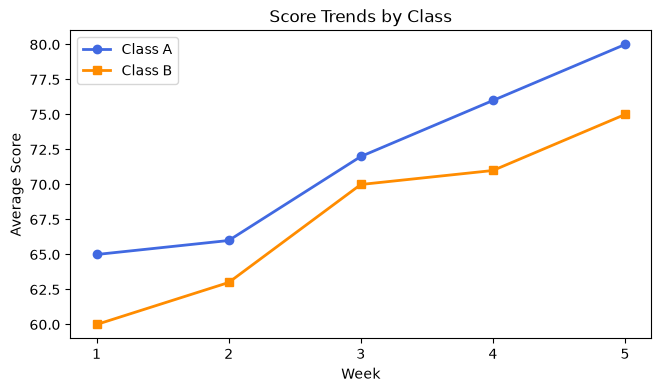

In [21]:
class_a = np.array([65, 66, 72, 76, 80])
class_b = np.array([60, 63, 70, 71, 75])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(weeks, class_a, color="royalblue", marker="o", linewidth=2, label="Class A")
ax.plot(weeks, class_b, color="darkorange", marker="s", linewidth=2, label="Class B")
#ax set bisa digabung
ax.set(title="Score Trends by Class", xlabel="Week", ylabel="Average Score")
ax.set_xticks(weeks)
ax.legend()
plt.show()

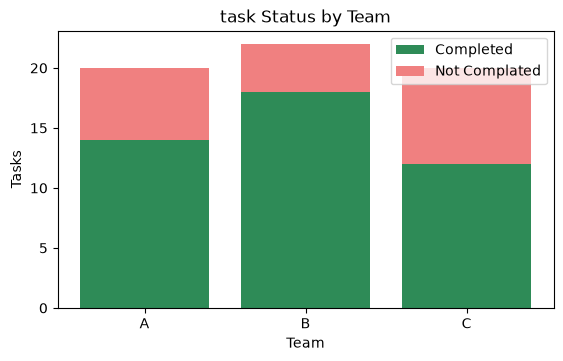

In [27]:
team = np.array(["A", "B", "C"])
complated = np.array([14, 18, 12])
not_complated = np.array([6, 4, 8])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.bar(team, complated, label="Completed", color="seagreen")
ax.bar(team, not_complated, bottom=complated, label="Not Complated", color="lightcoral")
ax.set(title="task Status by Team", xlabel="Team", ylabel="Tasks")

ax.legend()
plt.show()

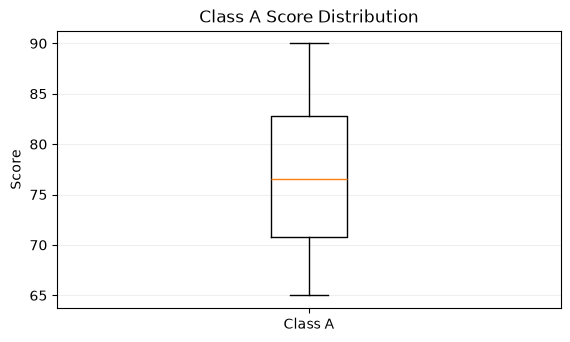

In [31]:
scores = np.array([65, 68, 70, 71, 74, 75, 78, 80, 82, 85, 87, 90])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
# segitiga adalah means jika showmeans true
ax.boxplot(scores)
ax.set_xticks([1], ["Class A"])
ax.set(title="Class A Score Distribution", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

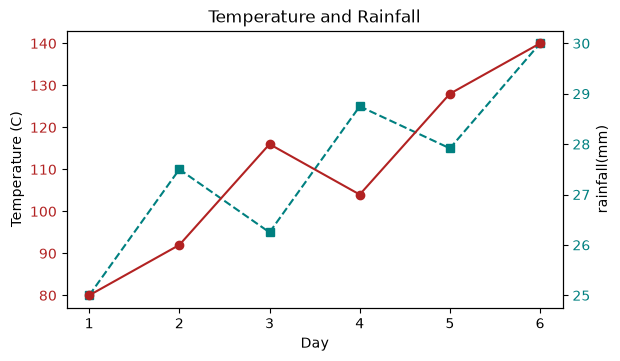

In [35]:
day = np.array([1, 2, 3, 4, 5, 6])
temperature = np.array([25, 26, 28, 27, 29, 30])
rainfall = np.array([80, 110, 95, 125, 115, 140])

fig, ax1 = plt.subplots(figsize=(6.4, 3.6))
ax2 = ax1.twinx()

ax1.plot(day, rainfall, color="teal", marker="s", linestyle="--")
ax2.plot(day, temperature, color="firebrick", marker="o")

ax1.set(title="Temperature and Rainfall", xlabel="Day", ylabel="Temperature (C)")
ax2.set_ylabel("rainfall(mm)")
ax1.tick_params(axis="y", labelcolor="firebrick")
ax2.tick_params(axis="y", labelcolor="teal")
plt.show()

### 3.3 Creating Stacked Bar Charts

**Stacked bar chart** menampilkan komposisi setiap kategori. Pada grafik berikut, bagian bawah adalah jumlah nilai ≥75, sedangkan bagian atas adalah nilai di bawah 75. Jumlah kedua segmen sama dengan ukuran kelas.

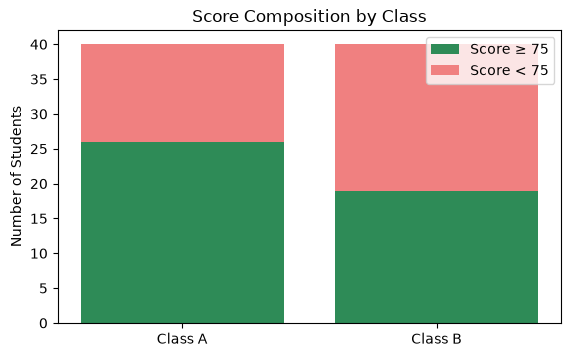

In [19]:
below_counts = np.array([(scores_a < 75).sum(), (scores_b < 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(categories, pass_counts, label="Score ≥ 75", color="seagreen")
ax.bar(categories, below_counts, bottom=pass_counts, label="Score < 75", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()

In [20]:
below_counts

array([14, 21])

Kode bottom=pass_counts` menempatkan batang di atas data sebelumnya (stacked bar), `label` memberi keterangan, dan `color` mengatur warna batang.

### 3.4 Understanding Histograms

**Histogram** menggambarkan distribusi data numerik dengan membagi nilai ke dalam beberapa interval (*bins*). Berbeda dari bar chart kategori, batang histogram mewakili interval nilai yang berurutan. Mengubah `bins` dapat mengubah tingkat kerincian grafik.

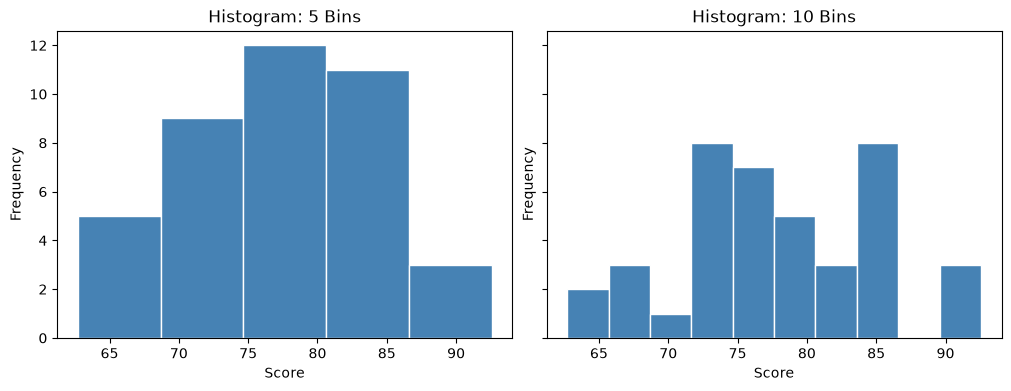

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [5, 10]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

Kode  `sharey=True` menyamakan skala sumbu Y pada kedua grafik, `layout="constrained"` mengatur tata letak agar tidak saling bertumpuk

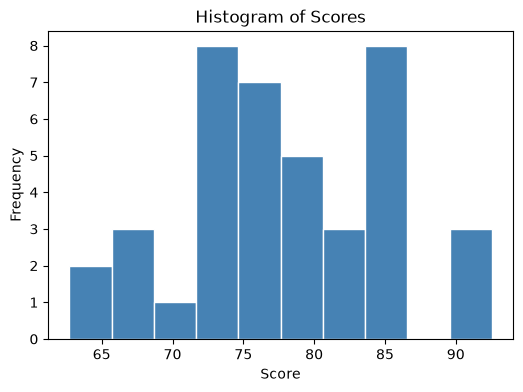

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    scores_a,
    bins=10,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    title="Histogram of Scores",
    xlabel="Score",
    ylabel="Frequency"
)
plt.show()

### 3.5 Comparing Distributions with Boxplots

**Boxplot** merangkum median, kuartil, dan sebaran data. Garis di dalam kotak adalah **median**, batas kotak menunjukkan **Q1–Q3**, sedangkan titik di luar *whisker* dapat ditandai sebagai pencilan.

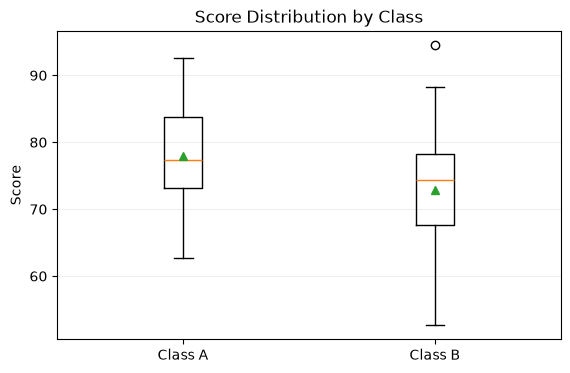

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

### 3.6 Exploring Relationships with Scatter Plots

**Scatter plot** dipakai untuk melihat pola hubungan dua variabel numerik. Satu titik adalah satu pengamatan. Pada contoh simulasi ini, X merupakan jam belajar dan Y merupakan nilai ujian.

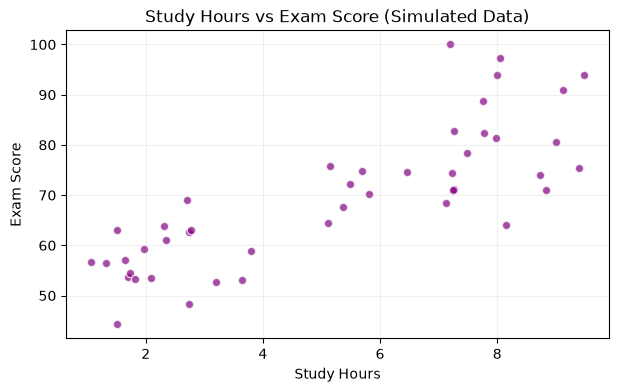

Pearson correlation: 0.81


In [24]:
# buat data baru
study_hours = rng.uniform(1, 10, size=45)
exam_scores = np.clip(48 + 4.3 * study_hours + rng.normal(0, 9, size=45), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)

plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

---
## 4. Saving Figures

### 4.1 Choosing a Plot Style

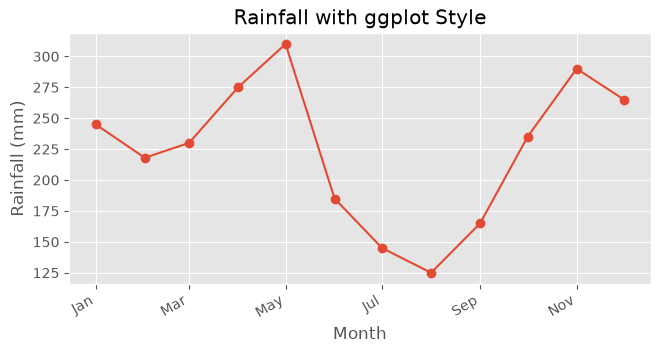

In [29]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

`with plt.style.context("ggplot")` menerapkan gaya tampilan grafik ggplot secara sementara. Pengaturan ini hanya berlaku di dalam blok `with` dan akan kembali ke gaya sebelumnya setelah blok selesai.

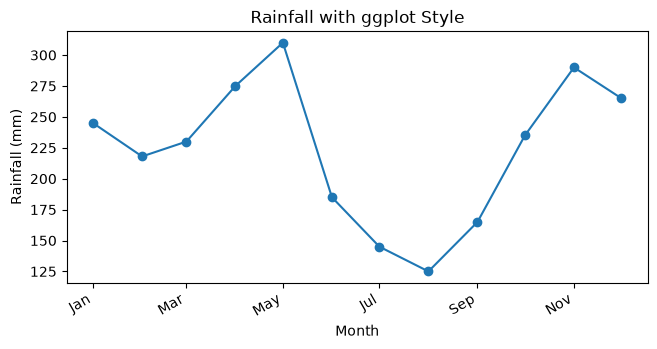

In [30]:
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

### 4.2 Saving PNG, PDF, and SVG Files

Gunakan `fig.savefig()` untuk menyimpan gambar. **PNG** adalah gambar raster, sedangkan **PDF** dan **SVG** cocok untuk grafik berbasis vektor. `dpi=300` mengatur resolusi saat menyimpan PNG, dan `bbox_inches="tight"` membantu mengurangi bagian kosong atau label terpotong.

Kode berikut otomatis membuat folder `week12_figures` di lokasi notebook dijalankan.

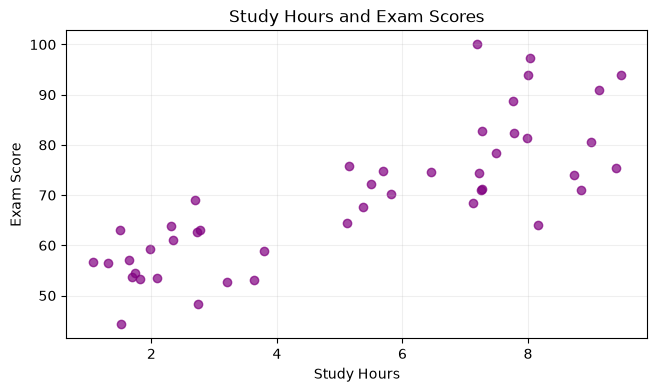

Saved to: C:\Users\Admin\Python Anaconda\Jupyter\week12_figures


In [32]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(study_hours, exam_scores, alpha=0.7, color="purple")
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.svg", bbox_inches="tight")
plt.show()
print("Saved to:", output_dir.resolve())

### 4.3 Adjusting Figure Size and Resolution

`figsize=(8, 4)` menentukan ukuran gambar dalam **inci**, bukan piksel. Ketika disimpan sebagai PNG dengan `dpi=300`, ukuran nominal 8 × 4 inci setara dengan sekitar 2400 × 1200 piksel, sebelum penyesuaian `bbox_inches="tight"`.

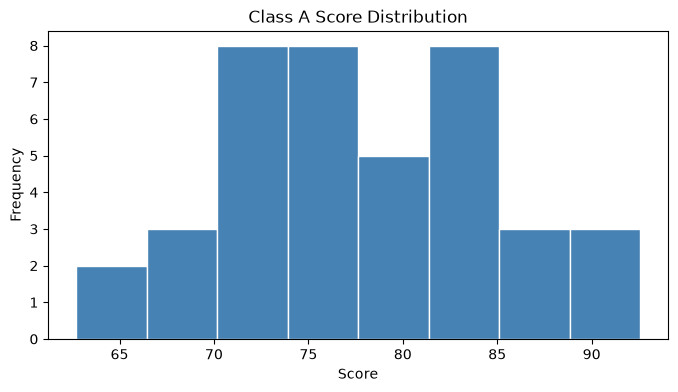

File: week12_figures\week12_histogram_300dpi.png
File size: 54.1 KB


In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_a, bins=8, edgecolor="white", color="steelblue")
ax.set(title="Class A Score Distribution", xlabel="Score", ylabel="Frequency")
file_path = output_dir / "week12_histogram_300dpi.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()
print("File:", file_path)
print("File size:", round(file_path.stat().st_size / 1024, 1), "KB")

### 4.4 Checking Saved Files

Sebelum menyerahkan hasil, pastikan file benar-benar tersimpan. Gunakan `Path.exists()` untuk memeriksa keberadaan file, lalu buka gambar jika perlu memeriksa apakah judul dan label terbaca.

In [34]:
for name in ["week12_scatter.png", "week12_scatter.pdf", "week12_scatter.svg",
             "week12_histogram_300dpi.png"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

week12_scatter.png: Found
week12_scatter.pdf: Found
week12_scatter.svg: Found
week12_histogram_300dpi.png: Found


---
## 5. Independent Student Exercises


### Exercise 1 — Basic Line Plot

Gunakan data berikut:

```python
weeks = [1, 2, 3, 4, 5]
visitors = [120, 135, 128, 150, 165]
```

1. Buat grafik garis dengan `fig, ax = plt.subplots()` dan `ax.plot()`.
2. Tambahkan marker bulat, judul, serta label sumbu X dan Y dalam **bahasa Inggris**.
3. Sebutkan minggu dengan jumlah pengunjung tertinggi.


Highest visitors: Week 5


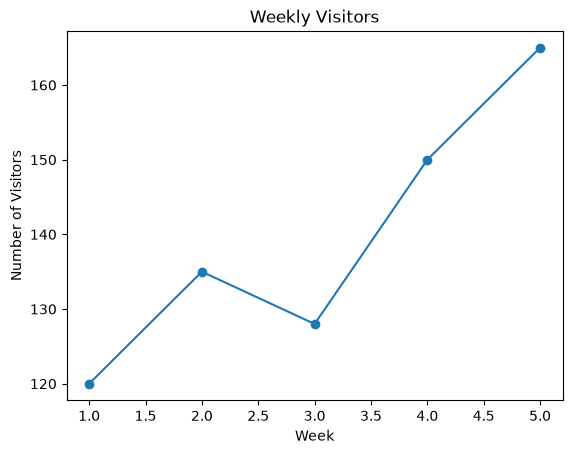

In [36]:
weeks = [1, 2, 3, 4, 5]
visitors = [120, 135, 128, 150, 165]

fig, ax = plt.subplots(); ax.plot(weeks, visitors, marker="o")
ax.set(title="Weekly Visitors", xlabel="Week", ylabel="Number of Visitors")
print("Highest visitors: Week", weeks[visitors.index(max(visitors))])
plt.show()

### Exercise 2 — Comparing Two Time Series

Gunakan data berikut (simulasi):

```python
dates = pd.date_range("2026-01-01", periods=6, freq="MS")
station_a = [180, 200, 190, 230, 210, 240]
station_b = [160, 170, 185, 205, 195, 220]
```

1. Buat **dua garis** dalam satu grafik dengan warna, `label`, dan `legend` berbeda.
2. Atur label tanggal supaya mudah dibaca.
3. Identifikasi bulan ketika kedua stasiun memiliki selisih terbesar.


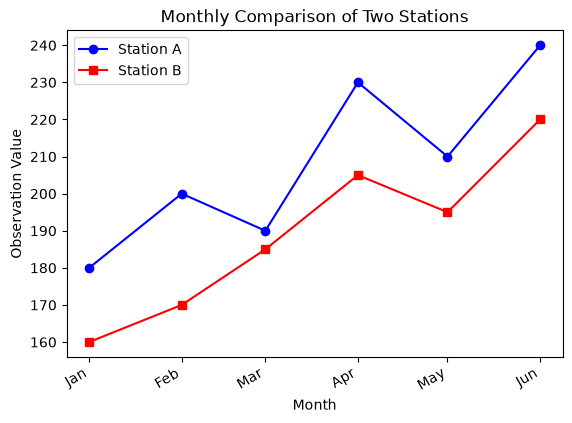

Largest difference: February = 30


In [37]:
dates = pd.date_range("2026-01-01", periods=6, freq="MS")
station_a = [180, 200, 190, 230, 210, 240]
station_b = [160, 170, 185, 205, 195, 220]

fig, ax = plt.subplots()
ax.plot(dates, station_a, color="blue", label="Station A", marker="o")
ax.plot(dates, station_b, color="red", label="Station B", marker="s")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set(title="Monthly Comparison of Two Stations", xlabel="Month", ylabel="Observation Value")
ax.legend(); fig.autofmt_xdate(); plt.show()
differences = np.abs(np.array(station_a)-np.array(station_b))
print("Largest difference:", dates[np.argmax(differences)].strftime("%B"), "=", differences.max())

### Exercise 3 — Bar Charts and Stacked Bars

Gunakan data kategori berikut:

```python
departments = ["A", "B", "C"]
completed = np.array([28, 35, 30])
not_completed = np.array([12, 5, 10])
```

1. Buat **bar chart** yang memperlihatkan jumlah `completed`.
2. Buat **stacked bar chart** menggunakan `bottom=completed`.
3. Beri judul, label sumbu, dan legenda yang jelas.

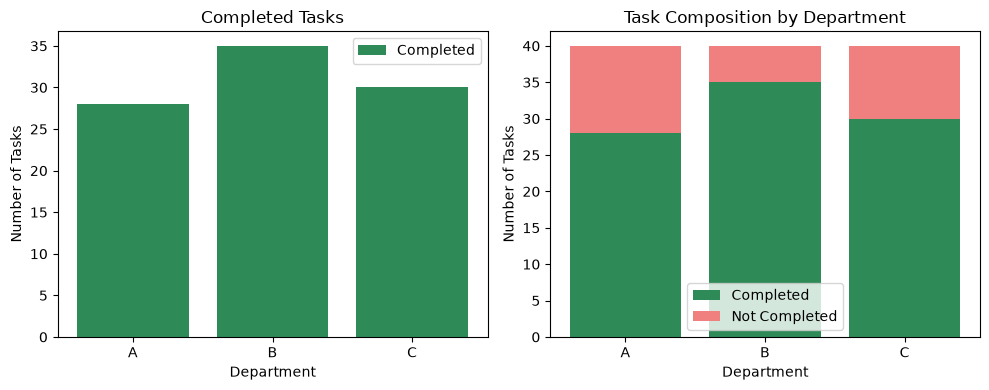

In [38]:
departments = ["A", "B", "C"]
completed = np.array([28, 35, 30])
not_completed = np.array([12, 5, 10])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(departments, completed, color="seagreen", label="Completed")
ax[0].set(title="Completed Tasks", xlabel="Department", ylabel="Number of Tasks")
ax[0].legend(); ax[1].bar(departments, completed, label="Completed", color="seagreen")
ax[1].bar(departments, not_completed, bottom=completed, label="Not Completed", color="lightcoral")
ax[1].set(title="Task Composition by Department", xlabel="Department", ylabel="Number of Tasks")
ax[1].legend(); plt.tight_layout()
plt.show()

### Exercise 4 — Histogram and Boxplot

Gunakan kembali `scores_a` dan `scores_b` dari Section 3.

1. Buat histogram `scores_a` dengan `bins=6` dan `bins=12`.
2. Bandingkan bentuk histogram keduanya dalam satu kalimat.
3. Buat boxplot dua kelas dan bandingkan median secara visual.

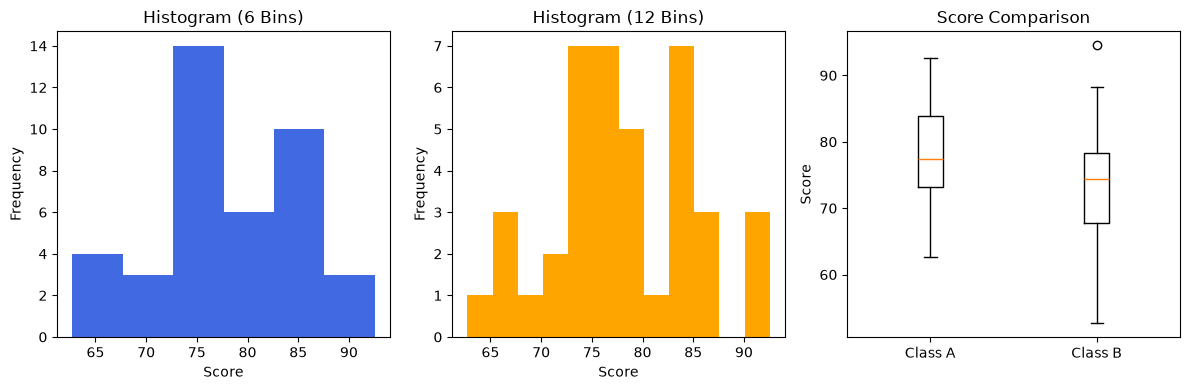

The 12-bin histogram shows more detail, while the 6-bin histogram provides a broader overview.
Median Class A: 77.337570118204 | Median Class B: 74.33567382201724


In [40]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].hist(scores_a, bins=6, color="royalblue")
ax[0].set(title="Histogram (6 Bins)", xlabel="Score", ylabel="Frequency")
ax[1].hist(scores_a, bins=12, color="orange")
ax[1].set(title="Histogram (12 Bins)", xlabel="Score", ylabel="Frequency")
ax[2].boxplot([scores_a, scores_b], tick_labels=["Class A", "Class B"])
ax[2].set(title="Score Comparison", ylabel="Score"); plt.tight_layout()
plt.show()
print("The 12-bin histogram shows more detail, while the 6-bin histogram provides a broader overview.")
print("Median Class A:", np.median(scores_a), "| Median Class B:", np.median(scores_b))

### Exercise 5 — Scatter Plot
Gunakan kembali `study_hours`, `exam_scores`, `scores_a`, dan `scores_b`.

1. Buat scatter plot antara jam belajar dan nilai ujian.
2. Jelaskan apakah arah hubungan terlihat positif, negatif, atau tidak jelas.

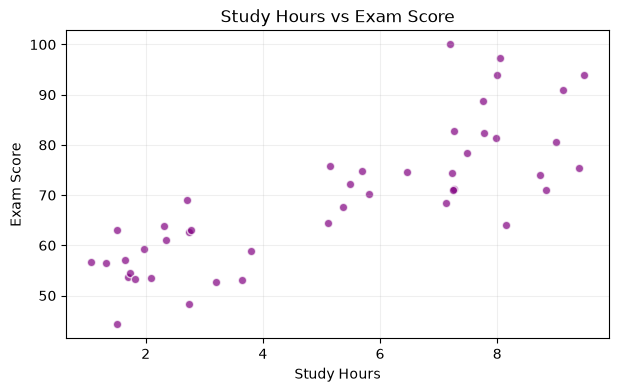

Pearson correlation: 0.81
Relationship: Positive


In [41]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)
plt.show()
corr = np.corrcoef(study_hours, exam_scores)[0, 1]
print("Pearson correlation:", round(corr, 3))
print("Relationship:", "Positive" if corr > 0 else "Negative" if corr < 0 else "No clear relationship")

### Exercise 6 — Saving a Publication-Ready Figure

1. Pilih salah satu grafik yang sudah dibuat.
2. Atur ukuran `figsize=(8, 4)` dan tambahkan judul serta label yang sesuai.
3. Simpan sebagai **PNG (300 dpi)** dan **PDF** dengan `bbox_inches="tight"`.
4. Pastikan kedua file berhasil dibuat dan jelaskan perbedaan kegunaannya.

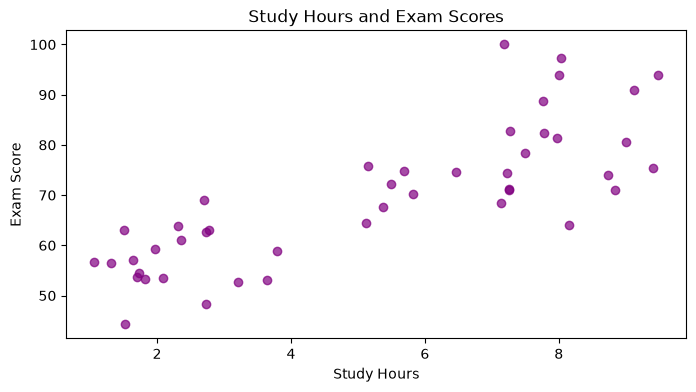

PNG created: True | PDF created: True


In [42]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7)
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
fig.savefig(output_dir / "exercise6.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "exercise6.pdf", bbox_inches="tight")
plt.show()
print("PNG created:", (output_dir / "exercise6.png").exists(), "| PDF created:", (output_dir / "exercise6.pdf").exists())